In [1]:
#Import library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from minisom import MiniSom 
from sklearn.metrics import silhouette_score

In [2]:
from pathlib import Path

def data_path(name):
    """Resolve a file in the project's data/ directory from any depth."""
    d = Path.cwd()
    for _ in range(5):
        if (d / "data" / name).exists():
            return d / "data" / name
        d = d.parent
    raise FileNotFoundError(f"data/{name} not found above {Path.cwd()}")

#Upload file excel
filedata = data_path("penguins.csv")
readexcel = pd.read_csv(filedata)
df= pd.DataFrame(readexcel)
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
#Preprocessing
#Drop data null
df_clean = df.dropna()
#Encoding sex (male:1 female: 0)
le = LabelEncoder()
df_clean['sex'] = le.fit_transform(df_clean['sex'])
#Standarisasi
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean)
#PCA
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

<tmp>\ipykernel_4004\718682733.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['sex'] = le.fit_transform(df_clean['sex'])


In [4]:
#SOM
som_size = 10
som = MiniSom(x=som_size, y=som_size, input_len=df_pca.shape[1], sigma=1.0, learning_rate=0.5)
som.train_random(df_pca, 10000, verbose=True)
win_map = np.array([som.winner(x) for x in df_pca])
som_clusters = win_map[:, 0] * som_size + win_map[:, 1]

 [  9191 / 10000 ]  92% - 0:00:00 left 

 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 0.09860355419516231


In [5]:
#Silhoutte
silhouette_avg = silhouette_score(df_pca, som_clusters)
print(f'Silhouette Score for SOM clustering: {silhouette_avg}')

Silhouette Score for SOM clustering: 0.3453509558435585


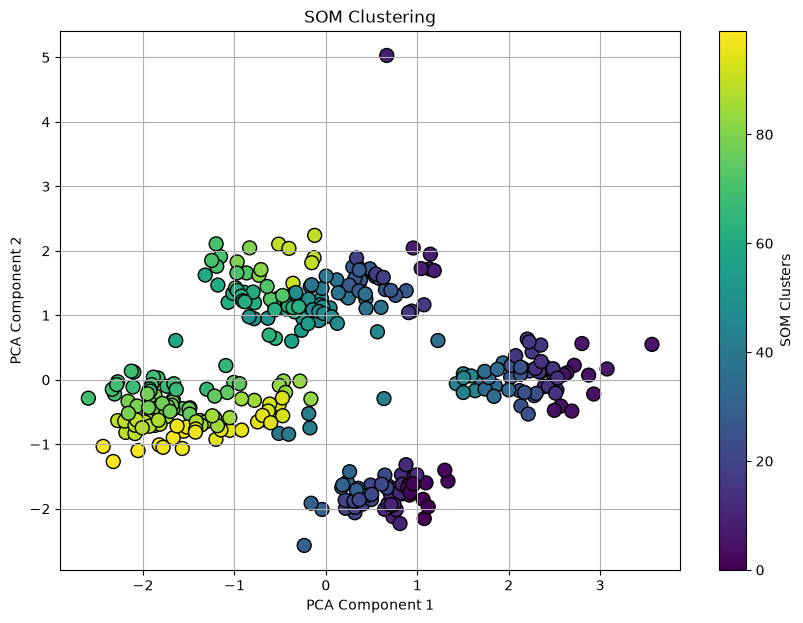

In [6]:
#Visualisasi
plt.figure(figsize=(10, 7))
plt.scatter(df_pca[:, 0], df_pca[:, 1], c=som_clusters, cmap='viridis', marker='o', edgecolor='k', s=100)
plt.title('SOM Clustering')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='SOM Clusters')
plt.grid(True)
plt.show()